# prePilot Memory screen analysis

Audit the optional memory screen separately from the four experimental blocks. The notebook reconstructs the selection result, checks recorded materials and geometry, distinguishes retries from final omissions, and compares order memory within the same session.

| Step | Evidence | Result |
|---|---|---|
| Consolidate sessions | Run identity and overlapping recorded rows | One checkpoint and its final export count as one run |
| Reconstruct selection | Studied items, displayed pair, choice and timeout | Independent correct count under the retained 6 of 10 criterion |
| Audit delivery | Recorded geometry and saved material arrays | Explicit checks for direction balance, hidden drone and item separation |
| Describe responses | Final answers and attempt history | Accuracy, final omissions and retry timing remain distinct |
| Compare main memory | Main encoding order and displayed items from the same run | Descriptive order accuracy without a screening validity claim |

The [design notebook](../../design_checks/notebooks/06_memory_screen.ipynb) explains the assigned material. This notebook evaluates observed data.

## Inputs and privacy

Raw exports are the default. The shared loader checks cumulative snapshots before selecting one canonical run, retains separate legacy sessions, and never pools raw exports with clean copies. An explicit clean mode is available for a deliberately selected collection. Missing assignment flags remain unknown.

Public displays and exported audit tables use ordinal session labels. Raw identifiers, filenames and demographics remain outside notebook outputs. All observations remain in audit tables even when a screen is incomplete or fails a check.

`DRONE_INPUT_MODE` selects raw or clean input. An explicit `DRONE_CLEAN_DIR` selects clean mode by default unless the input mode is explicitly set to raw. `DRONE_DERIVED_DIR` redirects audit tables and figures. These environment values prefill the editable controls in the next cell.

In [1]:
from pathlib import Path
import sys
import math
import io
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'static/task/memory_screening').is_dir() and (path / 'analysis').is_dir())
sys.path.insert(0, str(ROOT / 'analysis/memory_screen'))
from memory_screen_analysis import load_screen_data, runtime_design, analyze_screen_data, plot_report, export_report

# Environment values prefill these editable notebook controls.
CLEAN_OVERRIDE = os.environ.get('DRONE_CLEAN_DIR')
INPUT_MODE = os.environ.get('DRONE_INPUT_MODE', 'clean' if CLEAN_OVERRIDE else 'raw')
RAW_DIRS = None
CLEAN_DIR = Path(CLEAN_OVERRIDE).expanduser().resolve() if CLEAN_OVERRIDE and INPUT_MODE == 'clean' else None
FOCAL_SESSION = None
WRITE_EXPORTS = True
OUTPUT_DIR = Path(os.environ.get('DRONE_DERIVED_DIR', ROOT / 'analysis/data/prePilot/memory_screen/derived')).expanduser().resolve()
FIGURE_DIR = OUTPUT_DIR / 'figures'
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
                     'figure.dpi': 110, 'savefig.dpi': 180, 'axes.titlepad': 11})
pd.set_option('display.max_colwidth', 64)
expected = runtime_design()
data = load_screen_data(raw_dir=RAW_DIRS, clean_dir=CLEAN_DIR, mode=INPUT_MODE)
report = analyze_screen_data(data, expected)

## Session inventory

A checkpoint is a recovery snapshot rather than another participant. Legacy sessions without screen rows or assignment metadata do not enter the screening denominator. Counts below are sessions, which need not be independent people.

In [2]:
sessions = report['sessions']
display(sessions[['session', 'source_schema', 'snapshot_count', 'status',
                  'n_encoding', 'n_questions', 'n_correct', 'n_issues']].rename(columns={
    'session': 'Session', 'source_schema': 'Schema', 'snapshot_count': 'Source snapshots',
    'status': 'Screen status', 'n_encoding': 'Encoding rows', 'n_questions': 'Order questions',
    'n_correct': 'Correct', 'n_issues': 'Audit issues'}))
assigned = sessions[sessions.assigned.eq(True)]
print(f'{len(sessions)} canonical runs and {len(assigned)} assigned or observed screening assessments')
if len(report['intake_issues']):
    display(report['intake_issues'])
else:
    print('No source consolidation discrepancies')

,Session,Schema,Source snapshots,Screen status,Encoding rows,Order questions,Correct,Audit issues
0,Session 001,legacy,1,assignment_unknown,0,0,NaN,0
1,Session 002,legacy,1,assignment_unknown,0,0,NaN,0
2,Session 003,current,2,complete_pass,20,10,6.0,0


3 canonical runs and 1 assigned or observed screening assessments
No source consolidation discrepancies


## Selection result

Correctness is reconstructed from the item at the earlier studied position, the two images actually displayed, the selected side and the final timeout flag. The saved correct count and pass flag are checked against that reconstruction. A complete protocol requires 20 completed turns, 10 unique questions, valid answer keys and coverage of all 20 studied items.

The criterion remains at least 6 correct answers out of 10. A timeout followed by a successful retry is not a final omission. Technical problems remain visible rather than being relabelled as poor memory.

In [3]:
if len(assigned):
    display(assigned[['session', 'n_encoding_completed', 'n_questions', 'n_correct',
                      'saved_n_correct', 'recomputed_pass', 'n_final_timeouts', 'n_any_timeouts', 'n_issues']]
            .rename(columns={'session': 'Session', 'n_encoding_completed': 'Completed turns',
                'n_questions': 'Questions', 'n_correct': 'Reconstructed correct',
                'saved_n_correct': 'Saved correct', 'recomputed_pass': 'Meets criterion',
                'n_final_timeouts': 'Final timeouts', 'n_any_timeouts': 'Questions with a timeout',
                'n_issues': 'Audit issues'}))
    display(report['versions'])
    if len(report['audit_issues']):
        display(report['audit_issues'])
    else:
        print('Saved screening results, recorded answer keys and protocol checks agree')
else:
    print('No observed screening assessments. No behavioral estimates are invented.')

,Session,Completed turns,Questions,Reconstructed correct,Saved correct,Meets criterion,Final timeouts,Questions with a timeout,Audit issues
2,Session 003,20,10,6.0,6.0,True,0,3,0


,module_version,series_version,item_version,n_assigned,n_complete,n_pass
0,ms-3.4.0-2026-10-25,ms-hidden-medium-v5,ms-objects-normed-g2,1,1,1


Saved screening results, recorded answer keys and protocol checks agree


## Geometry and item delivery

Positions are checked against the arrays saved with each session. Comparison with the live design is performed only when its series version matches the recorded version. Direction counts include the initial move from the recorded baseline. The fixed drone shift and supply offset were designed from reference midpoints of mean nonzero drone movements and mean absolute landing offsets. Their medium labels do not prove that the delivered screen lies between the observed condition specific values in every export. The main task audit flags an apparent mismatch between saved volatility labels and realized movement sizes. Use recorded trajectories and version specific calculations for that comparison. The checks here verify delivery of the assigned geometry and do not resolve the condition label mapping.

Recorded stimulus identities are checked for uniqueness and overlap with the same run’s main stimuli. A missing display outcome is not evidence that an image rendered successfully. A false preload failure flag alone cannot establish successful display.

In [4]:
geometry = report['geometry']
geometry = geometry[geometry.geometry_rows.gt(0)] if len(geometry) else geometry
if len(geometry):
    display(geometry[['session', 'series_version', 'n_left', 'n_right',
                      'supply_n_left', 'supply_n_right', 'mean_abs_residual']]
            .rename(columns={'session': 'Session', 'series_version': 'Recorded series',
                'n_left': 'Drone left', 'n_right': 'Drone right', 'supply_n_left': 'Supply left',
                'supply_n_right': 'Supply right', 'mean_abs_residual': 'Mean absolute offset in pp'}).round(4))
    check_labels = {
        'saved_geometry_matches': 'Observed positions match saved arrays',
        'current_geometry_matches': 'Matching version agrees with runtime design',
        'constant_step_contract': 'Equal drone shifts with 10 left and 10 right',
        'movement_log_matches': 'Per turn movement metadata agree',
        'summary_motion_matches': 'Summary movement metadata agree',
        'supply_balance_contract': 'Supply lands 10 left and 10 right',
        'offset_magnitude_contract': 'Supply offset magnitude matches contract',
        'supply_log_matches': 'Per turn supply metadata agree',
        'summary_supply_matches': 'Summary supply metadata agree',
        'drone_visibility_matches': 'Drone hidden metadata agree'}
    checks = [dict(Session=row.session, Check=label, Observed=row[field])
              for _, row in geometry.iterrows() for field, label in check_labels.items()]
    display(pd.DataFrame(checks))
    display(report['material_audit'].rename(columns={
        'session': 'Session', 'n_encoding_rows': 'Screen turns', 'n_unique_screen_items': 'Unique screen items',
        'n_unique_main_items': 'Unique main items', 'n_shared_item_identities': 'Shared identities',
        'n_display_outcome_recorded': 'Recorded display outcomes', 'n_preload_failures': 'Recorded preload failures'}))
else:
    print('No recorded screen geometry to audit')

,Session,Recorded series,Drone left,Drone right,Supply left,Supply right,Mean absolute offset in pp
2,Session 003,ms-hidden-medium-v5,NaN,NaN,10.0,10.0,2.9573


,Session,Check,Observed
0,Session 003,Observed positions match saved arrays,True
1,Session 003,Matching version agrees with runtime design,None
2,Session 003,Equal drone shifts with 10 left and 10 right,None
3,Session 003,Per turn movement metadata agree,None
4,Session 003,Summary movement metadata agree,None
5,Session 003,Supply lands 10 left and 10 right,None
6,Session 003,Supply offset magnitude matches contract,None
7,Session 003,Per turn supply metadata agree,None
8,Session 003,Summary supply metadata agree,None
9,Session 003,Drone hidden metadata agree,None


,Session,Screen turns,Unique screen items,Unique main items,Shared identities,Recorded display outcomes,Recorded preload failures
0,Session 003,20,20,200,0,0,0


## Questions and timing

The serial gap is the difference between studied positions, so gap 2 contains one intervening item. Final answer RT measures the successful answer attempt. Total question duration also includes earlier attempts and the timeout feedback interval. The response deadline applies to each attempt rather than to that total duration.

The table retains every recorded question. The exported gap, pair and item summaries remain stratified by module, trajectory and item versions. Item summaries describe the pairs involving an item and do not estimate an item’s independent memorability.

In [5]:
questions = report['questions']
if len(questions):
    timing = questions[['session', 'pair_index', 'serial_gap', 'correct_side', 'choice_side',
                        'correct', 'n_attempts', 'n_timeout_attempts', 'rt_ms', 'total_duration_ms']].copy()
    timing['rt_ms'] = timing.rt_ms / 1000
    timing['total_duration_ms'] = timing.total_duration_ms / 1000
    display(timing.rename(columns={'session': 'Session', 'pair_index': 'Question', 'serial_gap': 'Serial gap',
        'correct_side': 'Earlier side', 'choice_side': 'Chosen side', 'correct': 'Correct',
        'n_attempts': 'Attempts', 'n_timeout_attempts': 'Timeout attempts',
        'rt_ms': 'Final attempt seconds', 'total_duration_ms': 'Total seconds'}).round(3))
else:
    print('No screening questions available')

,Session,Question,Serial gap,Earlier side,Chosen side,Correct,Attempts,Timeout attempts,Final attempt seconds,Total seconds
0,Session 003,1.0,3.0,left,left,1,2,1,2.488,10.489
1,Session 003,2.0,2.0,left,left,1,2,1,2.092,10.105
2,Session 003,3.0,3.0,right,right,1,1,0,2.959,2.959
3,Session 003,4.0,3.0,right,right,1,1,0,1.893,1.893
4,Session 003,5.0,3.0,right,right,1,1,0,2.424,2.424
5,Session 003,6.0,2.0,left,right,0,1,0,1.468,1.468
6,Session 003,7.0,3.0,left,right,0,1,0,2.459,2.459
7,Session 003,8.0,2.0,right,left,0,2,1,1.004,9.011
8,Session 003,9.0,3.0,right,right,1,1,0,3.926,3.926
9,Session 003,10.0,2.0,left,right,0,1,0,3.281,3.281


## Same session comparison

Main order accuracy is independently reconstructed from each block’s observed encoding order and its displayed pair. Final omissions remain incorrect in the denominator when the answer key is valid. Screening and main blocks differ in list length, materials, gaps and retention interval. Similar accuracy cannot validate the screen, and a single session cannot establish that screening improves later memory.

In [6]:
comparison = report['main_comparison']
if len(comparison):
    shown = comparison[['session', 'stage', 'n_questions', 'n_valid_keys', 'n_correct', 'accuracy',
                        'n_omissions', 'n_audit_issues']].copy()
    shown['accuracy'] = 100 * shown.accuracy
    display(shown.rename(columns={'session': 'Session', 'stage': 'Stage', 'n_questions': 'Questions',
        'n_valid_keys': 'Verified keys', 'n_correct': 'Correct', 'accuracy': 'Accuracy percent',
        'n_omissions': 'Final omissions', 'n_audit_issues': 'Audit issues'}).round(1))
    for label, part in comparison[comparison.stage.ne('Screen')].groupby('session'):
        print(f'{label} main order memory {int(part.n_correct.sum())} of {int(part.n_questions.sum())} correct')
else:
    print('No main order memory from an observed screening session')

,Session,Stage,Questions,Verified keys,Correct,Accuracy percent,Final omissions,Audit issues
0,Session 003,Screen,10,10,6,60.0,0,0
1,Session 003,Main block 1,14,14,7,50.0,0,0
2,Session 003,Main block 2,14,14,8,57.1,0,0
3,Session 003,Main block 3,14,14,9,64.3,0,0
4,Session 003,Main block 4,14,14,9,64.3,0,0


Session 003 main order memory 33 of 56 correct


## Comparative figures and exports

The first figure links observed trajectory, landing positions, item order and tested pairs. The second distinguishes retry timing, descriptive side and gap checks, and order accuracy across the same run’s main blocks. Side and gap panels regroup the same answers rather than independent samples. The dotted accuracy line is the binary guessing benchmark.

By default the figures show the last observed screening session in the canonical inventory. Set `FOCAL_SESSION` to another public session label when needed. Audit tables retain all sessions. Figures are embedded below and exported as PNG files under `analysis/data/prePilot/memory_screen/derived/figures/`.

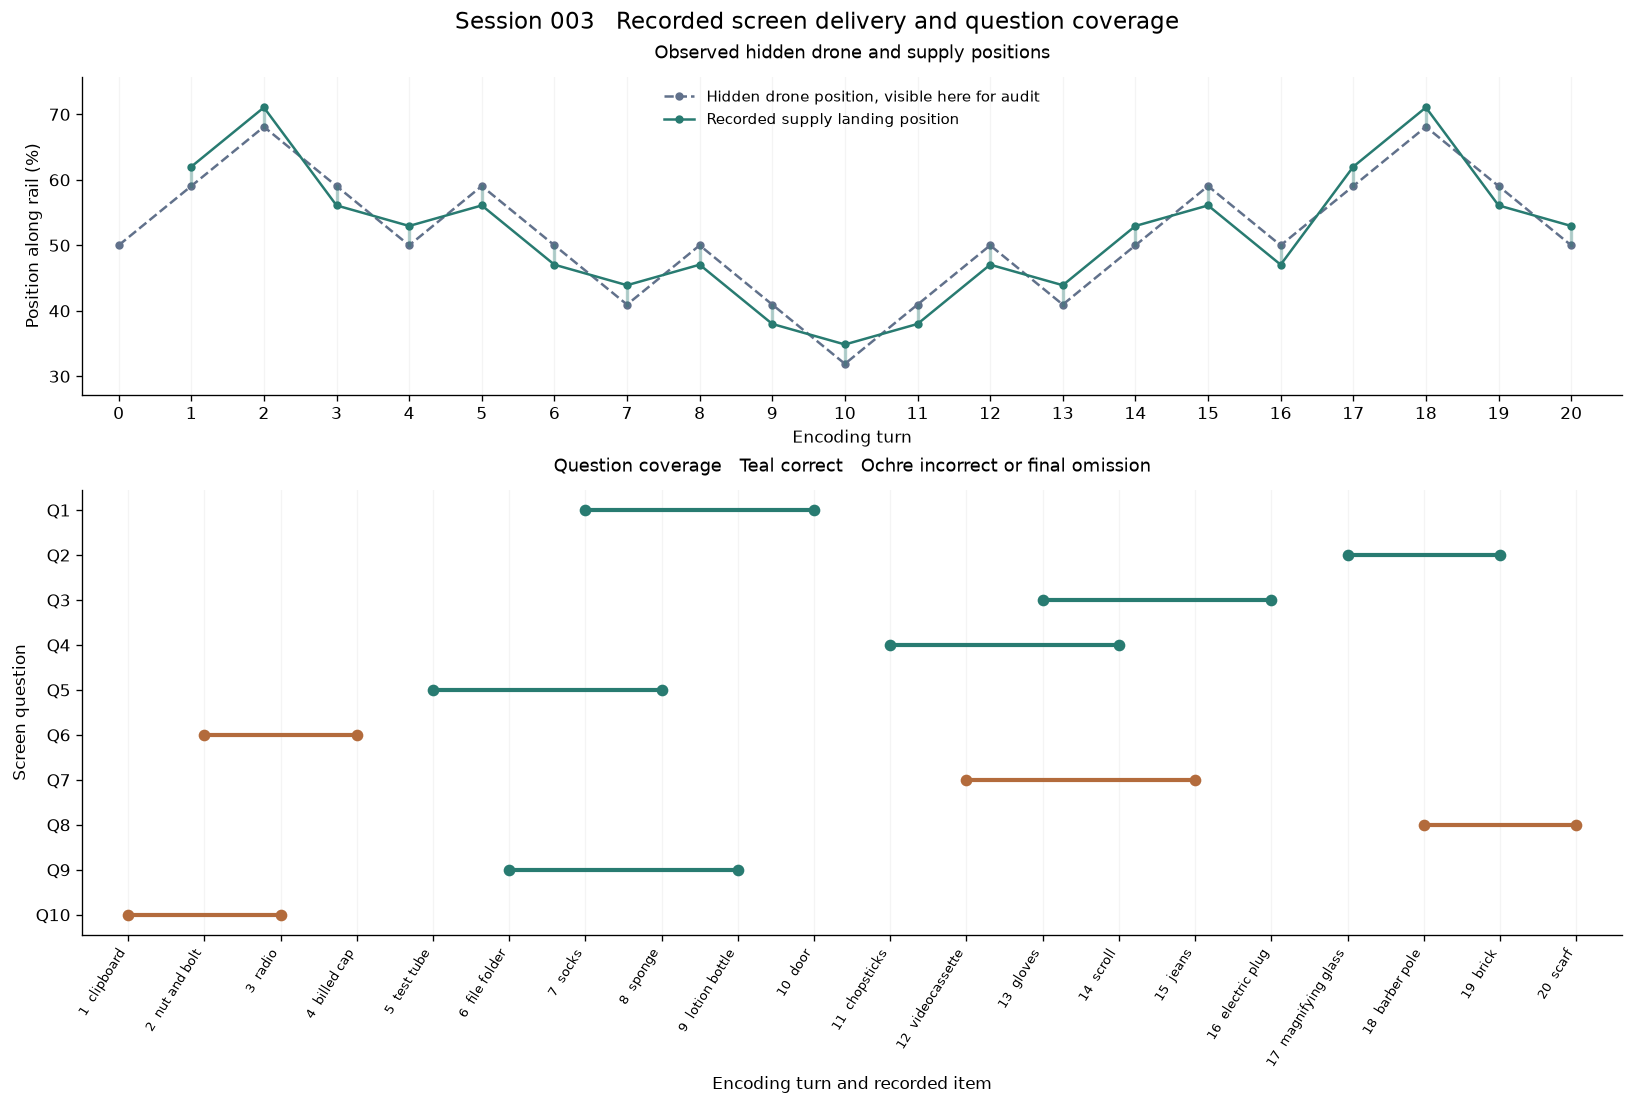

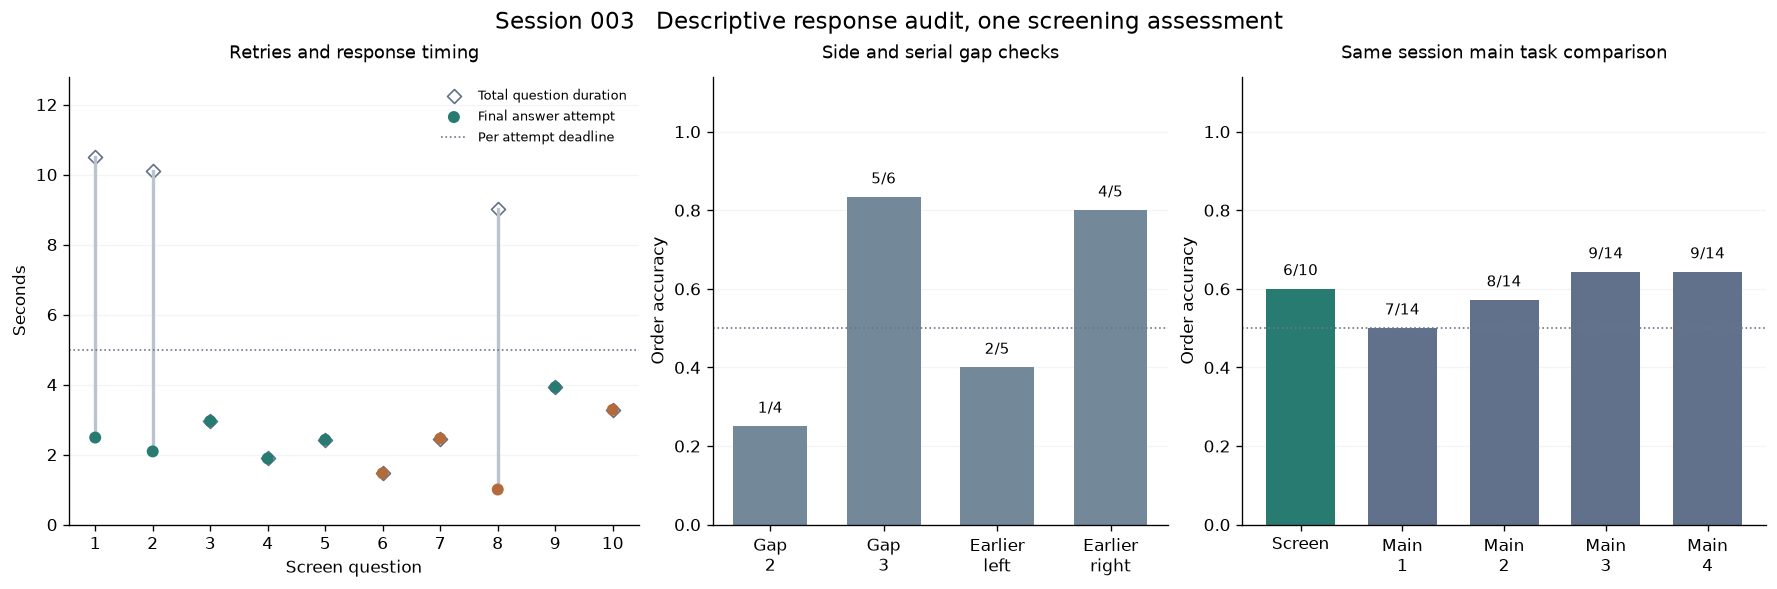

Exported 15 audit tables and 2 observed data figures
Audit tables and figures written to the configured output folder


In [7]:
figures = plot_report(report, session=FOCAL_SESSION)
for name, figure in figures:
    buffer = io.BytesIO()
    figure.savefig(buffer, format='png', dpi=120, bbox_inches='tight', facecolor='white')
    display(Image(data=buffer.getvalue()))
    if WRITE_EXPORTS:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        figure.savefig(FIGURE_DIR / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.close(figure)
if WRITE_EXPORTS:
    paths = export_report(report, OUTPUT_DIR)
    print(f'Exported {len(paths)} audit tables and {len(figures)} observed data figures')
    print('Audit tables and figures written to the configured output folder')

## Interpretation

The current criterion is permissive. Under independent unbiased binary guesses, the probability of at least 6 correct answers out of 10 is approximately 37.7 percent. This is a property of the rule rather than evidence about this participant’s strategy. Passing does not establish attentive encoding or strong memory.

The current data contain one screening assessment. They support delivery and reconstruction checks, with descriptive within session comparisons. Screening validity, exclusion benefit, item effects and population performance require a larger prespecified evaluation. Missing render outcomes, interrupted sessions and audit discrepancies should be resolved explicitly before making scientific exclusions.

In [8]:
chance_pass = sum(math.comb(10, correct) for correct in range(6, 11)) / 2**10
print(f'Independent guessing pass probability {chance_pass:.4%}')
print(f'Observed screening assessments {len(assigned)}')
print('No population effect or screening validity estimate is computed')

Independent guessing pass probability 37.6953%
Observed screening assessments 1
No population effect or screening validity estimate is computed
